# Questions about building the AR4 arm

A person building the AR4 robot arm works from a 377-page manual. At each assembly step they look at a bench photo and its printed instruction and ask what the step needs: how many screws and which kind, which part goes in, which tool. On the parts-list pages they ask for facts, such as how many of one screw the whole robot needs. Each question is answered by reading an image and a sentence together, which is the input a vision-language model (VLM) takes.

In this assignment you measure how well [SmolVLM-256M-Instruct](https://arxiv.org/abs/2504.05299) answers these questions without training. You then fine-tune it in three ways and compare them. [LoRA](https://arxiv.org/abs/2106.09685) adds trainable low-rank matrices beside frozen attention and MLP weights. [DoRA](https://arxiv.org/abs/2402.09353) splits each of those weights into a magnitude and a direction and applies the low-rank update to the direction only. [LayerNorm tuning](https://arxiv.org/abs/2312.11420) trains nothing but the scale of the normalization layers. The first two train about three million parameters, the third about thirty-five thousand, out of 256 million.

In [1]:
%pip install -q -U "transformers>=5" peft pymupdf datasets

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import hashlib
import inspect
import json
import marshal
import re
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf
import torch
from datasets import load_dataset
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from transformers.utils import logging as hf_logging

hf_logging.disable_progress_bar()
warnings.filterwarnings("ignore", message="Unsupported layer type")  # RMSNorm under LayerNorm tuning

## Settings

Keep these values for the runs you hand in. `TRAIN_LIMIT` and `TEST_LIMIT` are there so that you can check your code on a few pairs first.

In [3]:
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
DATASET_ID = "aegean-ai/ar4-assembly-vqa"
MANUAL_URL = "https://raw.githubusercontent.com/Annin-Robotics/downloads/main/2026/02/AR4-MK4-Robot-Manul-1.1.pdf"
MANUAL_SHA256 = "44d5d8d60a94078f28744d449008dd5a80ef52ce46a400607ebb02d3eb8a7fd1"
EPOCHS = 2  # passes over the training pairs, every method
LR = 2e-4  # AdamW learning rate, every method
ACCUM = 4  # pairs per optimizer step
IMAGE_EDGE = 512  # longest image side kept by the processor, in pixels
TRAIN_LIMIT = None  # None trains on every pair
TEST_LIMIT = None  # None scores every test pair
SETTINGS = {"dataset": DATASET_ID, "epochs": EPOCHS, "lr": LR, "accum": ACCUM, "image_edge": IMAGE_EDGE,
            "train_limit": TRAIN_LIMIT, "test_limit": TEST_LIMIT}  # a saved run is reused only under these and unchanged method code
RUNS = Path("runs")  # one CSV and one JSON per method
DEVICE = "cuda"
RUNS.mkdir(exist_ok=True)

## The manual and its images

Each row of the dataset names a page of the manual and a box on that page, in PDF points (1/72 inch). The image for a question is that box, rendered at 110 dots per inch. A step box covers a whole panel: the bench photo on the left and the printed instruction on the right. The answer to a step question is therefore printed inside its image, and the model has to find it there and tie it to what the photo shows. Documentation boxes cover a grid of labeled part photos or the fastener table.

The boxes were measured on version 1.1 of the manual. A later revision moves things around on its pages, so the download is checked against the SHA-256 digest of version 1.1 before any box is cut.

In [4]:
MANUAL = Path("AR4-MK4-Robot-Manul-1.1.pdf")
if not MANUAL.exists():
    urllib.request.urlretrieve(MANUAL_URL, MANUAL)
digest = hashlib.sha256(MANUAL.read_bytes()).hexdigest()
assert digest == MANUAL_SHA256, f"{MANUAL} is not version 1.1 of the manual (sha256 {digest})"
manual = pymupdf.open(MANUAL)
_images = {}


def render(page, bbox):
    # The image a dataset row refers to: its box on its page, at 110 dpi.
    key = (int(page), tuple(float(v) for v in bbox))
    if key not in _images:
        pix = manual[key[0] - 1].get_pixmap(clip=pymupdf.Rect(*key[1]), dpi=110)
        _images[key] = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
    return _images[key]


print(f"{manual.page_count} pages, digest matches version 1.1")

377 pages, digest matches version 1.1


## The question-answer pairs

Step questions (`kind` is `step`) come from the assembly chapter, pages 51 to 241. They ask for a fastener count or type, the part installed, a tool or material, a specification such as a wire length, an action, or the joint a step belongs to. Documentation questions (`kind` is `doc`) come from the parts list, pages 16 to 50. They ask what a photo in a grid is called, where a part sits in the grid, or how many of a fastener the whole robot needs.

Consecutive assembly steps reuse nearly the same photo, so a random split would put near-copies of test images into training. The split is by page instead. The assembly pages are cut into blocks of ten and every fifth block is held out for test. Training pages right beside a test block are dropped, and so are training pairs whose panel contains a photo that also appears in a test panel.

In [5]:
data = load_dataset(DATASET_ID)
train_df = data["train"].to_pandas()
test_df = data["test"].to_pandas()
if TRAIN_LIMIT:
    train_df = train_df.sample(TRAIN_LIMIT, random_state=0)
if TEST_LIMIT:
    test_df = test_df.sample(TEST_LIMIT, random_state=0)
print(f"{len(train_df)} training pairs, {len(test_df)} test pairs")
pairs = pd.concat([train_df.assign(split="train"), test_df.assign(split="test")])
pd.crosstab(pairs.qtype, [pairs.split, pairs.kind])

Generating train split:   0%|          | 0/1149 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/344 [00:00<?, ? examples/s]

1149 training pairs, 344 test pairs


split          test      train     
kind            doc step   doc step
qtype                              
action            2   53     2  185
count             2   37    14   95
fastener          0   20     0   52
fastener_count    0   21     0   53
fastener_list     0   19     0   49
joint             2   14     7   33
name             12    0    22    0
part              2   43     8  159
spec             10   63    40  258
table_count       9    0    25    0
tool              1   27     0  129
where             7    0    18    0

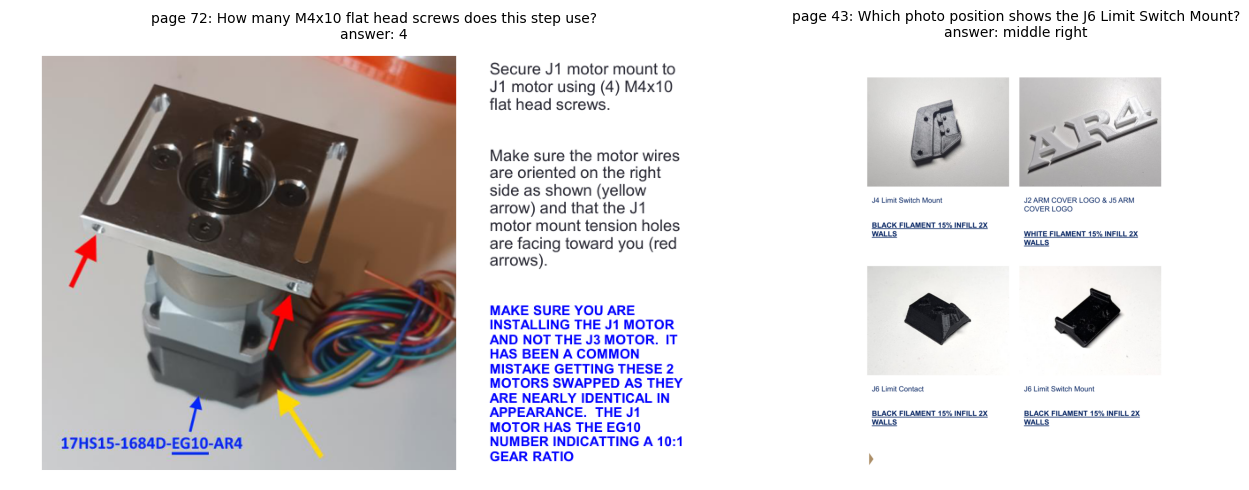

In [6]:
full_test = data["test"].to_pandas()
examples = [full_test[full_test.kind == "step"].iloc[0], full_test[full_test.qtype == "where"].iloc[0]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, row in zip(axes, examples):
    ax.imshow(render(row.page, row.bbox))
    ax.set_title(f"page {row.page}: {row.question}\nanswer: {row.answer}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Scoring answers

The answers are short: a count, a part name, a size. A model that says "toward the rear" when the reference says "toward rear" has the content right, but a plain string comparison marks it wrong. The graded score is therefore the normalized match. Both strings are lowercased, × becomes x, punctuation and brackets are removed, a number written with a leading decimal point gets a leading zero (so .375 and 0.375 match), the articles a, an and the are dropped, and the words that are left must be the same. Exact match, where the two strings are equal once surrounding spaces are trimmed, is reported beside it. The difference between the two tells you how much of a score comes from wording rather than content.

In [7]:
ARTICLES = {"a", "an", "the"}


def normalize(text):
    # Lowercase, x for ×, words and numbers only (decimals kept, .375 read as 0.375), articles dropped.
    words = re.findall(r"(?<![a-z0-9#.])\.\d+|[a-z0-9#]+(?:\.\d+)*", str(text).lower().replace("×", "x"))
    return " ".join("0" + w if w.startswith(".") else w for w in words if w not in ARTICLES)


def exact_match(pred, answer):
    return str(pred).strip() == str(answer).strip()


def normalized_match(pred, answer):
    return normalize(pred) == normalize(answer)


for pred, answer in [("toward the rear", "toward rear"), ("(1)", "1"), ("Terminal 20.", "20"), ("#6 x .375", "#6 X .375"), ("#6 x 0.375", "#6 x .375"), ("#6 x 375", "#6 x .375")]:
    print(f"{pred!r:20} {answer!r:14} exact {exact_match(pred, answer)!s:5}  normalized {normalized_match(pred, answer)}")

'toward the rear'    'toward rear'  exact False  normalized True
'(1)'                '1'            exact False  normalized True
'Terminal 20.'       '20'           exact False  normalized False
'#6 x .375'          '#6 X .375'    exact False  normalized True
'#6 x 0.375'         '#6 x .375'    exact False  normalized True
'#6 x 375'           '#6 x .375'    exact False  normalized False


## The model

SmolVLM-256M-Instruct joins a small image encoder to the SmolLM2 language model through a connector that turns image patches into tokens. Each image is resized so that its longer side is 512 pixels and read as a single tile. The question goes in as a chat turn with the image placed before the text, and the answer is generated greedily, at most 24 tokens long.

`evaluate` runs the model on a set of pairs and returns one row per pair, with the prediction and both scores.

In [8]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.image_processor.size = {"longest_edge": IMAGE_EDGE}


def load_model(dtype=torch.float32):
    return AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=dtype).to(DEVICE)


def chat(question, answer=None):
    # One user turn (image, then question), and the reference answer as the assistant turn when training.
    turns = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question + " Answer briefly."}]}]
    if answer is not None:
        turns.append({"role": "assistant", "content": [{"type": "text", "text": answer}]})
    return turns


@torch.no_grad()
def evaluate(model, df, max_new_tokens=24):
    model.eval()
    rows = []
    for r in df.itertuples():
        prompt = processor.apply_chat_template(chat(r.question), add_generation_prompt=True)
        x = processor(text=prompt, images=[render(r.page, r.bbox)], return_tensors="pt").to(DEVICE)
        x["pixel_values"] = x["pixel_values"].to(model.dtype)
        with torch.autocast("cuda", dtype=torch.float16):
            y = model.generate(**x, max_new_tokens=max_new_tokens, do_sample=False)
        pred = processor.batch_decode(y[:, x["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()
        rows.append({"id": r.id, "kind": r.kind, "qtype": r.qtype, "question": r.question,
                     "answer": r.answer, "pred": pred})
    return score(pd.DataFrame(rows))


def score(out):
    out["exact"] = [exact_match(p, a) for p, a in zip(out.pred, out.answer)]
    out["normalized"] = [normalized_match(p, a) for p, a in zip(out.pred, out.answer)]
    return out


def fingerprint(configure):
    # Identifies a method's code: the source of its configure function and the plain values it reads, such as TARGETS.
    if configure is None:
        return None  # zero-shot trains nothing
    try:
        code = inspect.getsource(configure)
    except (OSError, TypeError):
        code = marshal.dumps(configure.__code__).hex()  # the compiled function when its source is not available
    values = {n: repr(v) for n in configure.__code__.co_names
              if isinstance(v := configure.__globals__.get(n), (str, int, float, list, tuple, dict))}
    return hashlib.sha256((code + json.dumps(values, sort_keys=True)).encode()).hexdigest()


def is_saved(name, code=None):
    # A saved run counts only when it was made with the current SETTINGS and the same method code.
    meta = RUNS / f"{name}.json"
    if not ((RUNS / f"{name}.csv").exists() and meta.exists()):
        return False
    saved = json.loads(meta.read_text())
    return saved.get("settings") == SETTINGS and saved.get("code") == code


def load_run(name):
    # The saved predictions, scored again with the current metric.
    return score(pd.read_csv(RUNS / f"{name}.csv", dtype={"answer": str, "pred": str}, keep_default_na=False))

## Part 1: the zero-shot baseline (20 points)

The base model answers every test question before any training. Its results are saved as `runs/zeroshot.csv` so that Part 3 can compare it with the fine-tuned models.

In [9]:
ZEROSHOT = RUNS / "zeroshot.csv"
if is_saved("zeroshot"):
    zeroshot = load_run("zeroshot")
else:
    base = load_model(torch.float16)
    start = time.time()
    zeroshot = evaluate(base, test_df)
    zeroshot.to_csv(ZEROSHOT, index=False)
    (RUNS / "zeroshot.json").write_text(json.dumps({"method": "zeroshot", "trainable": 0, "peak_gib": 0.0,
                                                     "train_min": 0.0, "checkpoint_mb": 0.0, "losses": [],
                                                     "settings": SETTINGS, "code": None}))
    print(f"{len(zeroshot)} test pairs in {(time.time() - start) / 60:.1f} min")
    del base
    torch.cuda.empty_cache()
print(f"normalized match {zeroshot.normalized.mean():.3f}   exact match {zeroshot.exact.mean():.3f}")
zeroshot.sample(min(8, len(zeroshot)), random_state=1)[["qtype", "question", "answer", "pred"]]

344 test pairs in 2.1 min
normalized match 0.233   exact match 0.000


,qtype,question,answer,pred
306,joint,Which spindle receives the thrust washers and ...,J3 spindle,A3
341,joint,Which joint uses this gear head motor?,J2,HEX KEY Wrench.
291,joint,Which driver receives the blue pair of wire in...,J1 driver on the far left,Driver 1.
102,spec,Which terminal gets the stripe blue wire?,21,Terminal 2.
289,action,What does the 3D printed base interlock with?,the enclosure,The enclosure.
267,action,Which wire pair is untwisted?,The green pair,Green.
125,spec,Which terminal does the solid brown wire go to?,PUL,PUL.
11,fastener_count,How many 4mm X 20 socket head cap screws does ...,4,2.


Write `by_qtype`, which breaks a set of results down by question type, and `failure_kind`, which sorts each failed prediction into one of three kinds. A prediction that contains the right answer and more around it is a different failure from one that gives the wrong number, and the two call for different fixes.

In [10]:

def by_qtype(results):
    """Accuracy and number of questions by question type."""
    summary = results.groupby("qtype").agg(
        normalized=("normalized", "mean"),
        exact=("exact", "mean"),
        n=("qtype", "size")
    )
    return summary.sort_values("normalized", ascending=False)


def failure_kind(row):
    """Classify why a prediction failed normalized matching."""
    answer = normalize(row["answer"])
    prediction = normalize(row["pred"])

    if answer and answer in prediction:
        return "verbose"

    if re.fullmatch(r"\d+", answer):
        numbers = re.findall(r"\d+", prediction)
        if answer not in numbers:
            return "wrong number"

    return "other"


In [11]:
try:
    display(by_qtype(zeroshot))
    failed = zeroshot[~zeroshot.normalized]
    display(failed.apply(failure_kind, axis=1).value_counts().rename("failed pairs"))
except NotImplementedError as e:
    print(e)

,normalized,exact,n
qtype,,,
fastener_count,0.714286,0.0,21
count,0.589744,0.0,39
tool,0.357143,0.0,28
spec,0.287671,0.0,73
name,0.166667,0.0,12
joint,0.125000,0.0,16
action,0.072727,0.0,55
part,0.066667,0.0,45
fastener,0.000000,0.0,20


,failed pairs
other,210
wrong number,27
verbose,27


### 1. What the base model can and cannot do

Which question types does the base model already answer, and which does it fail? Use the per-type table and the failure kinds, and quote three predictions that show the pattern.

**Answer:**


### Question 1: What the Base Model Can and Cannot Do

The zero-shot baseline model achieved **23.3% normalized accuracy** on 344 test questions, while exact-match accuracy was **0%**.

The model performed best on **fastener_count (71.43%)** and **count (58.97%)** questions. It also showed some ability to answer **tool (35.71%)** and **spec (28.77%)** questions. However, it struggled with **action (7.27%)**, **part (6.67%)**, and **joint (12.50%)** questions. It achieved 0% accuracy on fastener, fastener_list, table_count, and where questions.

The failure analysis showed:
- **Other errors:** 210
- **Wrong-number errors:** 27
- **Verbose-answer errors:** 27

These results suggest that the model sometimes recognizes useful information but struggles with identifying specific parts, understanding assembly instructions, and producing precise answers.

#### Three Prediction Examples

1. **Question:** What does the 3D printed base interlock with?
   - Correct answer: the enclosure
   - Model prediction: The enclosure.
   - **Analysis:** The model identified the correct component, although the wording and punctuation differed.

2. **Question:** Which terminal does the solid brown wire go to?
   - Correct answer: PUL
   - Model prediction: PUL.
   - **Analysis:** The model recognized the correct technical label but added punctuation.

3. **Question:** How many 4mm X 20 socket head cap screws are needed?
   - Correct answer: 4
   - Model prediction: 2.
   - **Analysis:** The model predicted an incorrect screw count, showing difficulty with precise numerical information.

#### Conclusion

Overall, the base model performs better on simple counting questions than on detailed assembly instructions and part identification. Fine-tuning with LoRA, DoRA, and LayerNorm may improve its understanding of the assembly manual and its ability to generate accurate answers.


## Part 2: fine-tuning (50 points)

Every method trains on the same objective: the cross-entropy of the reference answer's tokens, given the image and the question. The prompt tokens are masked out of the loss, so the model learns to produce the answer instead of repeating the question. One pair is one forward pass, and the gradients of four pairs are added up before each optimizer step. The weights are stored in 32-bit floats while the forward pass runs in 16-bit floats, and the loss is scaled up before the backward pass so that small gradients do not round to zero in 16 bits.

`run_method(name, configure)` loads a fresh base model, passes it to your `configure` function, trains whatever `configure` left trainable, and scores the result on the test split. It records the trainable parameter count, peak GPU memory, training time and the size of the saved checkpoint in `runs/<name>.json`, and the per-pair results in `runs/<name>.csv`. A method whose files already exist is loaded instead of retrained, but only if they were made with the same settings and the same `configure` function. Change `TRAIN_LIMIT`, `TEST_LIMIT`, `EPOCHS` or another setting and the method is trained again. Fix a bug in `configure`, or in a value it reads such as `TARGETS`, and it is trained again too. If `configure` calls a helper function of yours and you change only the helper, pass `retrain=True` to train it again.

In [12]:
def train(model, df, epochs=EPOCHS, lr=LR, accum=ACCUM):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr)
    scaler = torch.amp.GradScaler()
    model.train()
    losses = []
    for epoch in range(epochs):
        order = df.sample(frac=1, random_state=epoch)
        for step, r in enumerate(order.itertuples()):
            image = render(r.page, r.bbox)
            full = processor.apply_chat_template(chat(r.question, r.answer))
            prompt = processor.apply_chat_template(chat(r.question), add_generation_prompt=True)
            x = processor(text=full, images=[image], return_tensors="pt").to(DEVICE)
            n_prompt = processor(text=prompt, images=[image], return_tensors="pt")["input_ids"].shape[1]
            labels = x["input_ids"].clone()
            labels[:, :n_prompt] = -100  # the loss covers the answer tokens only
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**x, labels=labels).loss
            scaler.scale(loss / accum).backward()
            if (step + 1) % accum == 0 or step + 1 == len(order):
                scaler.step(opt)
                scaler.update()
                opt.zero_grad()
            losses.append(loss.item())
            if step % 200 == 0:
                print(f"epoch {epoch} step {step} loss {loss.item():.3f}", flush=True)
    return losses


def run_method(name, configure, retrain=False):
    code = fingerprint(configure)
    if is_saved(name, code) and not retrain:
        print(f"{name}: loaded from {RUNS}")
        return load_run(name)
    torch.manual_seed(0)
    model = configure(load_model())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name}: {trainable:,} trainable parameters")
    torch.cuda.reset_peak_memory_stats()
    start = time.time()
    losses = train(model, train_df)
    minutes = (time.time() - start) / 60
    peak = torch.cuda.max_memory_allocated() / 2**30
    checkpoint = RUNS / name
    model.save_pretrained(checkpoint)
    size = sum(f.stat().st_size for f in checkpoint.rglob("*") if f.is_file()) / 2**20
    results = evaluate(model, test_df)
    results.to_csv(RUNS / f"{name}.csv", index=False)
    (RUNS / f"{name}.json").write_text(json.dumps({"method": name, "trainable": trainable, "peak_gib": peak,
                                                   "train_min": minutes, "checkpoint_mb": size, "losses": losses,
                                                   "settings": SETTINGS, "code": code}))
    print(f"{name}: normalized match {results.normalized.mean():.3f}, exact match {results.exact.mean():.3f}, "
          f"{minutes:.1f} min, peak {peak:.2f} GiB")
    del model
    torch.cuda.empty_cache()
    return results

Write the three `configure` functions. Each takes the base model and returns a model in which only the method's parameters are trainable. The parameter counts in the docstrings let you check your setup before you spend time training: `run_method` prints the count as soon as `configure` returns.

In [13]:

from peft import LoraConfig, LNTuningConfig, get_peft_model

# Target projection layers for LoRA and DoRA
TARGETS = [
    "q_proj", "k_proj", "v_proj", "o_proj",
    "gate_proj", "up_proj", "down_proj"
]

def lora(model):
    """LoRA with rank 8, alpha 8, dropout 0.1."""
    config = LoraConfig(
        r=8,
        lora_alpha=8,
        lora_dropout=0.1,
        target_modules=TARGETS,
        init_lora_weights="gaussian",
        bias="none",
        use_dora=False
    )
    return get_peft_model(model, config)


def dora(model):
    """DoRA with the same settings as LoRA."""
    config = LoraConfig(
        r=8,
        lora_alpha=8,
        lora_dropout=0.1,
        target_modules=TARGETS,
        init_lora_weights="gaussian",
        bias="none",
        use_dora=True
    )
    return get_peft_model(model, config)


def ln_tuning(model):
    """Train only the language model's normalization layers."""
    targets = [
        name for name, module in model.named_modules()
        if (
            name.startswith("model.text_model.")
            and (
                name.endswith("input_layernorm")
                or name.endswith("post_attention_layernorm")
                or name.endswith("norm")
            )
        )
    ]

    config = LNTuningConfig(target_modules=targets)
    return get_peft_model(model, config)


In [14]:

%pip uninstall -y torchao
%pip install -q -U "torchao>=0.16.0"


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [15]:

import importlib.metadata

try:
    print("torchao version:", importlib.metadata.version("torchao"))
except importlib.metadata.PackageNotFoundError:
    print("torchao is not installed")


torchao version: 0.18.0


### LoRA

In [16]:
try:
    run_method("lora", lora)
except NotImplementedError as e:
    print(e)

W1110 14:06:52.951000 427 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


lora: 2,884,608 trainable parameters
epoch 0 step 0 loss 6.514
epoch 0 step 200 loss 1.317
epoch 0 step 400 loss 1.003
epoch 0 step 600 loss 0.077
epoch 0 step 800 loss 0.487
epoch 0 step 1000 loss 0.169
epoch 1 step 0 loss 1.067
epoch 1 step 200 loss 0.896
epoch 1 step 400 loss 0.018
epoch 1 step 600 loss 0.117
epoch 1 step 800 loss 0.219
epoch 1 step 1000 loss 0.021
lora: normalized match 0.564, exact match 0.468, 14.3 min, peak 1.96 GiB


### DoRA

In [17]:
try:
    run_method("dora", dora)
except NotImplementedError as e:
    print(e)

dora: 3,067,776 trainable parameters
epoch 0 step 0 loss 6.514
epoch 0 step 200 loss 1.942
epoch 0 step 400 loss 0.840
epoch 0 step 600 loss 0.108
epoch 0 step 800 loss 0.284
epoch 0 step 1000 loss 0.086
epoch 1 step 0 loss 0.866
epoch 1 step 200 loss 1.349
epoch 1 step 400 loss 0.036
epoch 1 step 600 loss 0.120
epoch 1 step 800 loss 0.168
epoch 1 step 1000 loss 0.010
dora: normalized match 0.578, exact match 0.485, 22.9 min, peak 2.38 GiB


### LayerNorm tuning

In [18]:
try:
    run_method("ln_tuning", ln_tuning)
except NotImplementedError as e:
    print(e)

ln_tuning: 35,136 trainable parameters
epoch 0 step 0 loss 6.514
epoch 0 step 200 loss 2.958
epoch 0 step 400 loss 1.234
epoch 0 step 600 loss 0.569
epoch 0 step 800 loss 0.361
epoch 0 step 1000 loss 0.697
epoch 1 step 0 loss 1.096
epoch 1 step 200 loss 1.642
epoch 1 step 400 loss 1.442
epoch 1 step 600 loss 0.536
epoch 1 step 800 loss 1.372
epoch 1 step 1000 loss 1.316
ln_tuning: normalized match 0.392, exact match 0.326, 6.5 min, peak 1.40 GiB


## Part 3: comparing the methods (30 points)

`compare` collects every finished run from `runs/` into one table: the cost of each method next to both scores. A run counts as finished only if it was made with the current settings and the current version of its `configure` function, so an older run of code you have since fixed is left out. The plots below show the training loss of each method and its normalized match per question type.

In [19]:
METHODS = {"zeroshot": None, "lora": "lora", "dora": "dora", "ln_tuning": "ln_tuning"}  # the name of each configure function


def finished():
    # Only runs made with the current settings and each configure function as it is defined right now.
    return [m for m, fn in METHODS.items() if is_saved(m, fingerprint(globals()[fn] if fn else None))]


def compare():
    rows = []
    for m in finished():
        cost = json.loads((RUNS / f"{m}.json").read_text())
        res = load_run(m)
        rows.append({"method": m, "trainable": cost["trainable"], "peak GiB": round(cost["peak_gib"], 2),
                     "train min": round(cost["train_min"], 1), "checkpoint MB": round(cost["checkpoint_mb"], 1),
                     "normalized": round(res.normalized.mean(), 3), "exact": round(res.exact.mean(), 3)})
    return pd.DataFrame(rows).set_index("method")


compare()

,trainable,peak GiB,train min,checkpoint MB,normalized,exact
method,,,,,,
zeroshot,0,0.00,0.0,0.0,0.233,0.000
lora,2884608,1.96,14.3,11.1,0.564,0.468
dora,3067776,2.38,22.9,11.8,0.578,0.485
ln_tuning,35136,1.40,6.5,0.1,0.392,0.326


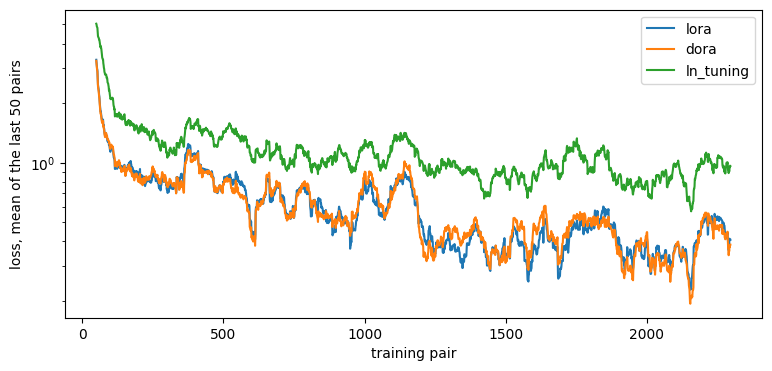

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
for m in finished():
    losses = pd.Series(json.loads((RUNS / f"{m}.json").read_text())["losses"])
    if len(losses):
        ax.plot(losses.rolling(50).mean(), label=m)
ax.set_xlabel("training pair")
ax.set_ylabel("loss, mean of the last 50 pairs")
ax.set_yscale("log")
ax.legend()
plt.show()

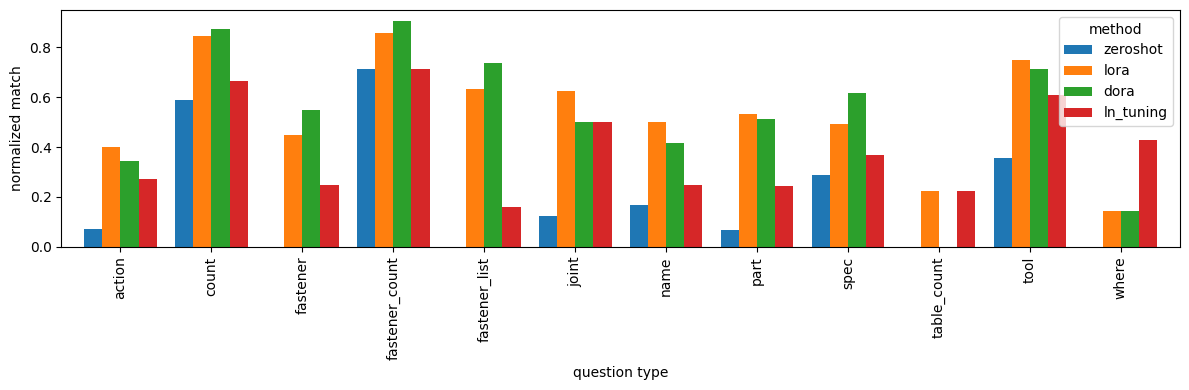

In [22]:
per_type = pd.DataFrame({m: load_run(m).groupby("qtype").normalized.mean() for m in finished()})
ax = per_type.plot.bar(figsize=(12, 4), width=0.8)
ax.set_ylabel("normalized match")
ax.set_xlabel("question type")
ax.legend(title="method")
plt.tight_layout()
plt.show()

In [25]:

from pathlib import Path
from zipfile import ZipFile
from google.colab import files

names = ["zeroshot", "lora", "dora", "ln_tuning"]
run_dir = Path("runs")
zip_path = Path("assignment3_results.zip")

required = [
    run_dir / f"{name}.{ext}"
    for name in names
    for ext in ("csv", "json")
]

missing = [str(p) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Missing required files: {missing}")

with ZipFile(zip_path, "w") as z:
    for path in required:
        z.write(path, arcname=f"runs/{path.name}")

print("ZIP created successfully with 8 result files.")
files.download(str(zip_path))


ZIP created successfully with 8 result files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 2. Choosing a method

Rank the three fine-tuning methods by normalized match and by cost: trainable parameters, peak memory, training time and checkpoint size. Which would you deploy, and why? You trained each method once, so say whether the gap between the two closest methods could come from the seed alone, and what you would run to find out.

**Answer:**

### Question 2: Choosing a Method

I compared LoRA, DoRA, and LayerNorm tuning based on normalized accuracy, trainable parameters, GPU memory, training time, and checkpoint size.

#### Performance Comparison

| Metric | LoRA | DoRA | LayerNorm |
|---|---:|---:|---:|
| Normalized Match | 56.4% | 57.8% | 39.2% |
| Exact Match | 46.8% | 48.5% | 32.6% |
| Trainable Parameters | 2,884,608 | 3,067,776 | 35,136 |
| Peak GPU Memory | 1.96 GiB | 2.38 GiB | 1.40 GiB |
| Training Time | 14.3 min | 22.9 min | 6.5 min |
| Checkpoint Size | 11.1 MB | 11.8 MB | 0.1 MB |

#### Ranking by Accuracy

1. **DoRA:** 57.8% normalized accuracy.
2. **LoRA:** 56.4% normalized accuracy.
3. **LayerNorm:** 39.2% normalized accuracy.

DoRA achieved the highest accuracy, followed closely by LoRA. LayerNorm performed significantly worse than both methods.

#### Ranking by Cost

For all four cost metrics, from lowest to highest:

1. **LayerNorm:** Fewest trainable parameters, lowest GPU memory, shortest training time, and smallest checkpoint.
2. **LoRA:** Moderate computational cost and checkpoint size.
3. **DoRA:** Highest computational cost and largest checkpoint.

#### Which Method Would I Deploy?

I would choose **LoRA** for deployment because it provides a good balance between accuracy and computational efficiency.

DoRA achieved 57.8% normalized accuracy compared with LoRA's 56.4%, a difference of only 1.4 percentage points. However, DoRA required 22.9 minutes of training compared with LoRA's 14.3 minutes. It also used more GPU memory (2.38 GiB versus 1.96 GiB) and had a slightly larger checkpoint (11.8 MB versus 11.1 MB).

LoRA therefore provides nearly the same accuracy with lower training cost and memory requirements. If maximum accuracy were the primary goal and computational resources were sufficient, DoRA would also be a reasonable choice.

LayerNorm is useful when computational resources and storage are extremely limited, but its lower accuracy makes it less suitable for this task.

#### Could the Accuracy Difference Be Due to the Random Seed?

Yes. The accuracy difference between DoRA (57.8%) and LoRA (56.4%) is small. Since each method was trained only once, the difference could be caused by random initialization, training-data order, or other sources of randomness.

To investigate this, I would train LoRA and DoRA using multiple random seeds, such as 0, 1, 2, 3, and 4, while keeping the dataset, epochs, learning rate, and other hyperparameters unchanged.

I would calculate the mean normalized accuracy and standard deviation for each method and compare the results across seeds. I would also examine paired predictions on the same test questions.

If DoRA consistently performs better across multiple runs, that would provide stronger evidence that its improvement is meaningful. Otherwise, the observed difference may be due to random variation.

#### Conclusion

DoRA achieved the highest accuracy, while LayerNorm had the lowest computational cost. LoRA offered the best overall balance of performance and efficiency in this experiment, making it my preferred deployment method.


### 3. Failure cases

Take your best method and pick five test pairs it gets wrong under the normalized match. Show the image, the question, the reference and the prediction for each in the cell below. For each one, say whether the reference, the normalization or the model is at fault.

**Answer:** _Write your answer here._

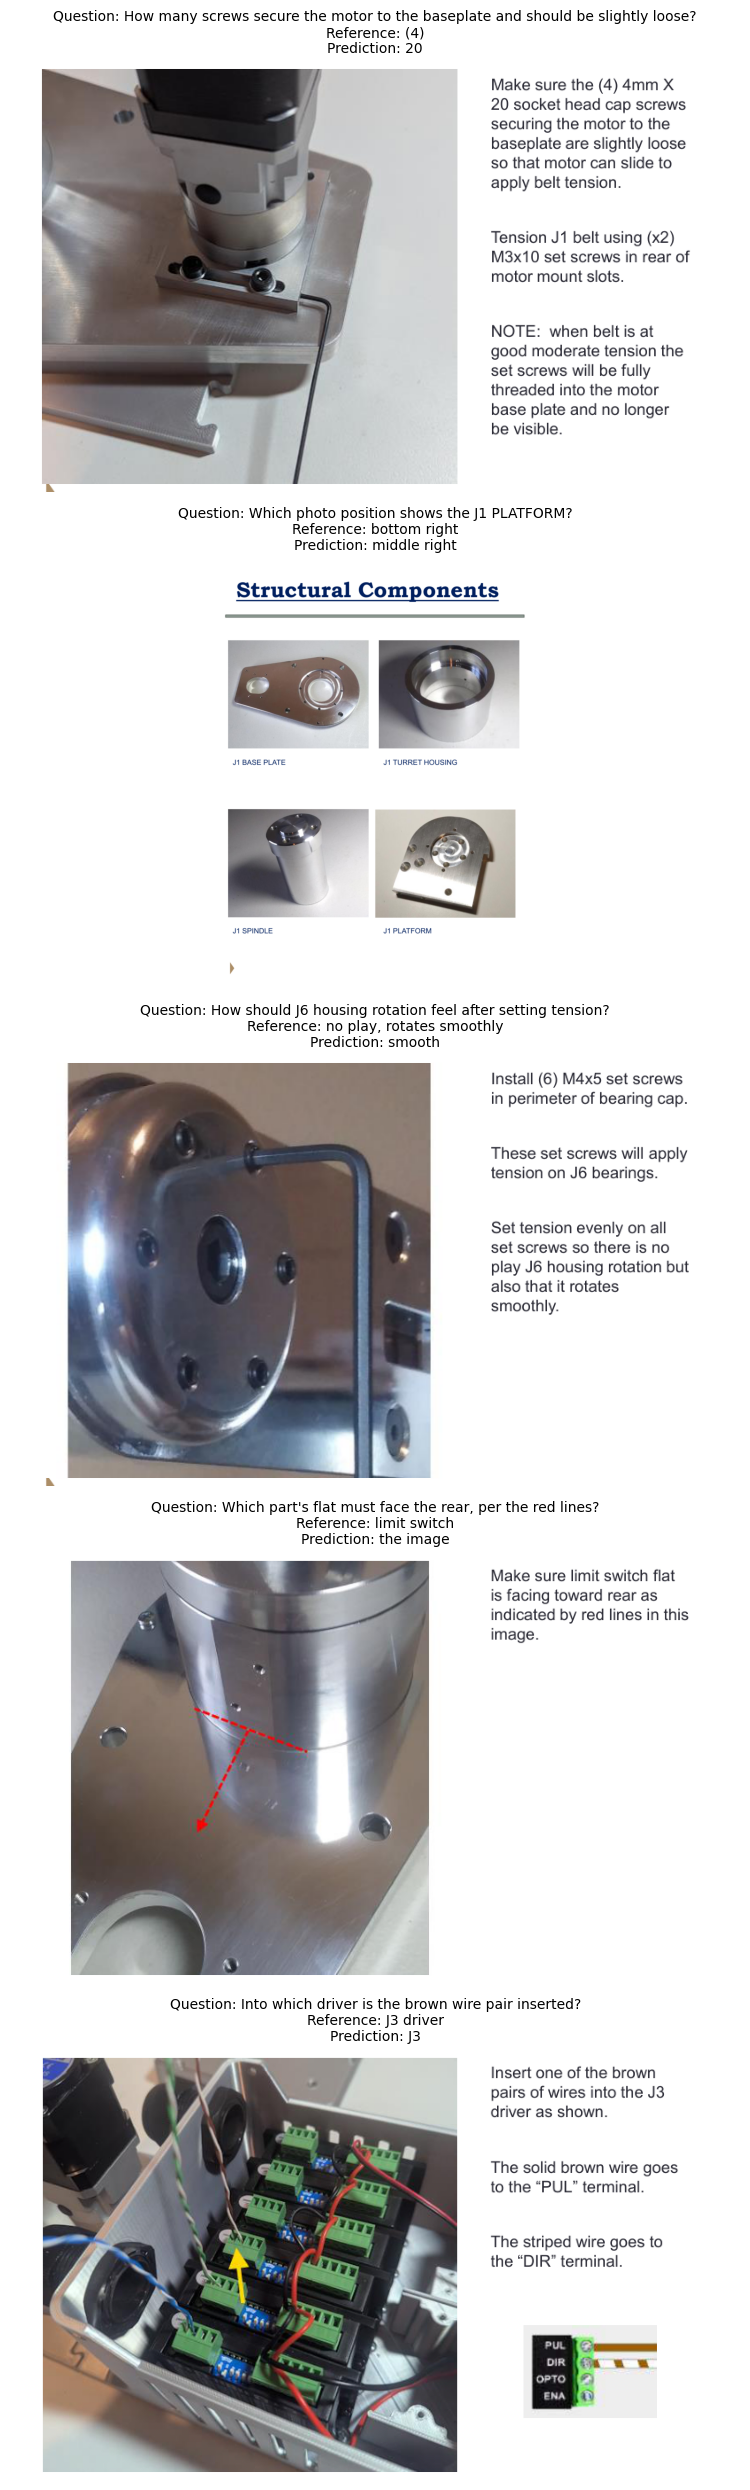


Failure Case 1
Question: How many screws secure the motor to the baseplate and should be slightly loose?
Reference: (4)
Prediction: 20
Failure Type: wrong number

Failure Case 2
Question: Which photo position shows the J1 PLATFORM?
Reference: bottom right
Prediction: middle right
Failure Type: other

Failure Case 3
Question: How should J6 housing rotation feel after setting tension?
Reference: no play, rotates smoothly
Prediction: smooth
Failure Type: other

Failure Case 4
Question: Which part's flat must face the rear, per the red lines?
Reference: limit switch
Prediction: the image
Failure Type: other

Failure Case 5
Question: Into which driver is the brown wire pair inserted?
Reference: J3 driver
Prediction: J3
Failure Type: other


In [24]:
# Five failure cases of your best method

# Question 3: Five failure cases from DoRA

import matplotlib.pyplot as plt
import pandas as pd

# Load saved DoRA results
results = load_run("dora").copy()

# Get the original test dataset containing page and bbox
test_data = data["test"].to_pandas().reset_index(drop=True)

# Match predictions with the original test questions
assert len(results) == len(test_data), "Test dataset size mismatch"

results = results.reset_index(drop=True)

# Verify that the rows are in the same order
assert (
    results["question"].astype(str).tolist()
    == test_data["question"].astype(str).tolist()
), "Question order mismatch"

# Add image location information
results["page"] = test_data["page"]
results["bbox"] = test_data["bbox"]

# Select five incorrect predictions
failed = results[~results["normalized"]].copy()
examples = failed.sample(n=5, random_state=42)

# Display five failure cases
fig, axes = plt.subplots(5, 1, figsize=(12, 25))

for ax, (_, row) in zip(axes, examples.iterrows()):
    image = render(row["page"], row["bbox"])

    ax.imshow(image)
    ax.set_title(
        f"Question: {row['question']}\n"
        f"Reference: {row['answer']}\n"
        f"Prediction: {row['pred']}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

# Print details for analysis
for i, (_, row) in enumerate(examples.iterrows(), 1):
    print(f"\nFailure Case {i}")
    print("Question:", row["question"])
    print("Reference:", row["answer"])
    print("Prediction:", row["pred"])
    print("Failure Type:", failure_kind(row))



### Question 3: Failure Cases

I analyzed five incorrect predictions from DoRA, which achieved the highest normalized accuracy of 57.8%. The examples show different problems involving numerical interpretation, visual identification, incomplete answers, and answer formatting.

#### Failure Case 1: Incorrect Screw Count

**Question:** How many screws secure the motor to the baseplate and should be slightly loose?

- Reference: (4)
- Prediction: 20
- Failure type: Wrong number
- **Cause: Model error**

The manual states that four M4x20 screws secure the motor to the baseplate. The model predicted 20, apparently confusing the screw length (20 mm) with the number of screws. The reference answer is correct, and normalization cannot fix this numerical error.

#### Failure Case 2: Incorrect Photo Position

**Question:** Which photo position shows the J1 PLATFORM?

- Reference: bottom right
- Prediction: middle right
- Failure type: Other
- **Cause: Model error**

The model selected the wrong position in the parts-list image. The reference identifies the J1 PLATFORM as bottom right, but the model predicted middle right. This indicates difficulty locating a specific component within a grid of photographs.

#### Failure Case 3: Incomplete Assembly Instruction

**Question:** How should J6 housing rotation feel after setting tension?

- Reference: no play, rotates smoothly
- Prediction: smooth
- Failure type: Other
- **Cause: Model error**

The manual explains that the housing should rotate smoothly without any play. The model captured the smooth-rotation requirement but omitted the important condition that there should be no play. The prediction is partially correct but incomplete. Normalized matching appropriately marks it incorrect because it omits required information.

#### Failure Case 4: Incorrect Part Identification

**Question:** Which part's flat must face the rear, per the red lines?

- Reference: limit switch
- Prediction: the image
- Failure type: Other
- **Cause: Model error**

The instruction states that the limit switch flat should face toward the rear. However, the model predicted "the image" instead of identifying the component. This suggests difficulty connecting the visual markings and written instruction to the correct part.

#### Failure Case 5: Incomplete Component Name

**Question:** Into which driver is the brown wire pair inserted?

- Reference: J3 driver
- Prediction: J3
- Failure type: Other
- **Cause: Normalization limitation / answer formatting**

The manual states that the brown wire pair is inserted into the J3 driver. The model predicted "J3", which identifies the correct driver but omits the word "driver".

The current normalization function requires the same words after normalization, so it marks this prediction incorrect. Semantically, "J3" is a reasonable abbreviated answer in the context of the question. A more flexible evaluation method could recognize this equivalence.

#### Conclusion

These five examples demonstrate that DoRA still makes mistakes despite improving overall accuracy.

The main problems include confusing measurements with quantities, selecting incorrect photo positions, omitting important conditions, and failing to identify components.

Four cases primarily reflect model errors, while the fifth illustrates a limitation of strict normalized matching. Improving visual grounding, numerical reasoning, and answer evaluation could help reduce these failures.


### 4. Leakage

Every step image shows its own printed instruction, and the test pairs come from page blocks that training never sees, with neighboring pages and shared photos removed.

1. Explain why a random split of the 1,493 pairs would have given a higher test score than this split, and why that score would mislead you.
2. Name one way information about the test pairs can still reach training under this split, and describe how you would measure its effect on the score.

**Answer:**


### Question 4: Leakage

#### 1. Why would a random split give a higher and misleading test score?

A random split of the 1,493 question-answer pairs would likely produce a higher test accuracy because many assembly steps contain very similar images, repeated components, and related instructions.

For example, consecutive pages of the AR4 assembly manual may show the same motor, screws, or mechanical parts from slightly different angles. With a random split, some of these nearly identical examples could appear in the training set while others appear in the test set.

As a result, the model might memorize specific images, instructions, or answers instead of learning how to understand new assembly steps.

This is called **data leakage** because information closely related to the test examples becomes available during training.

The resulting test accuracy would be misleading because it would overestimate the model's ability to answer questions about genuinely unseen assembly instructions.

The assignment uses a more careful page-based split. It separates training and testing pages into blocks, removes neighboring training pages, and excludes training examples containing photographs shared with test examples.

This produces a more realistic evaluation of how well the model generalizes to unfamiliar assembly steps.

#### 2. How could test information still leak into training, and how would I measure its effect?

One possible source of leakage is **repeated text or highly similar instructions across different pages**.

Even when neighboring pages and duplicate photographs are removed, different assembly steps may still contain similar sentences, component names, screw specifications, and instructions.

For example, the same fastener specification or assembly instruction might appear on multiple pages. The model could learn these repeated patterns during training and use them to answer related test questions.

To measure this effect, I would:

1. Compare the text of training and test questions and their associated manual instructions using similarity measures such as TF-IDF cosine similarity.
2. Identify test examples with highly similar training examples.
3. Create a stricter evaluation split by removing training examples with high textual similarity to the test examples.
4. Retrain the same model using the stricter split while keeping the model configuration, learning rate, epochs, and random seeds unchanged.
5. Compare normalized-match accuracy on the same held-out test questions before and after removing the overlapping examples.

If the accuracy decreases after removing highly similar training examples, this would suggest that repeated information was contributing to the original test performance.

However, a decrease alone would not prove leakage, because removing examples also reduces the amount of training data. To control for this, I would compare against a second experiment that removes the same number of randomly selected training examples.

#### Conclusion

A random train-test split would likely overestimate model performance because similar images and instructions could appear in both sets.

The page-based split reduces this risk, but repeated text and component information may still create overlap.

Using stricter similarity filtering and controlled experiments would help determine whether the model is genuinely generalizing or benefiting from information shared between training and testing examples.


## Submitting

Commit this file with every cell output saved, together with the CSV and JSON files in `runs/`, under `assignments/assignment-3` in your clone of the class repository. Leave out the checkpoint folders in `runs/`. Submit the GitHub URL of that folder, not the repository root.